# **Import python libraries**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np
print(np.__version__)
from scipy.signal import find_peaks
from datetime import datetime,date

2.1.3


In [ ]:
pip install optuna

# **Give google drive access**

In [ ]:
from google.colab import drive
# Unmount the drive if already mounted
drive.flush_and_unmount()

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
%cd "/content/drive/My Drive/Colab Notebooks/Ozonation model"

Mounted at /content/drive
/content/drive/My Drive/Colab Notebooks/Ozonation model


# **Calculate CT based on log removal (USEPA 2010)**

## **Remove NAN values of the selected parameters**



In [ ]:
# Select one parameter to remove NAN values
print("Available Parameters:", PIMS_LIMS.columns.tolist())
for i, param in enumerate(PIMS_LIMS.columns.tolist(), start=1):
         print(f"{i}: {param}")
selected_indices_3 = input("Select WQ parameters to remove NAN values: ").split(',')
selected_indices_3 = [int(index) - 1 for index in selected_indices_3]
selected_parameters_3 = [PIMS_LIMS.columns [i] for i in selected_indices_3]
PIMS_LIMS = PIMS_LIMS.dropna(subset=selected_parameters_3)
# Display the cleaned DataFrame
# print(PIMS_LIMS)

NameError: name 'PIMS_LIMS' is not defined

## **Calculate CT using USEPA**


In [ ]:
file_path = 'PIMSLIMSfinal2020-2025.xlsx'
PIMS_LIMS = pd.read_excel(file_path)

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/CTUSEPAcalc.ipynb"
PIMS_LIMS = CTcalc(PIMS_LIMS)

The desired log removal for Giardia is: 1
The desired log removal for Virus is: 1.8
The desired log removal for E.coli is: 2.1


In [ ]:
output_path = 'PIMSLIMSfinal2020-2025.xlsx'
PIMS_LIMS.to_excel(output_path, index=False)

In [ ]:
# Replace NAN values with the previous measured value
print("Available Parameters:", PIMS_LIMS.columns.tolist())
for i, param in enumerate(PIMS_LIMS.columns.tolist(), start=1):
         print(f"{i}: {param}")
selected_indices_2 = input("Select WQ parameters to fill NAN values: ").split(',')
selected_indices_2 = [int(index) - 1 for index in selected_indices_2]
selected_parameters_2 = [PIMS_LIMS.columns [i] for i in selected_indices_2]
PIMS_LIMS[selected_parameters_2] = PIMS_LIMS[selected_parameters_2].ffill()
# Select one parameter to remove NAN values
print("Available Parameters:", PIMS_LIMS.columns.tolist())
for i, param in enumerate(PIMS_LIMS.columns.tolist(), start=1):
         print(f"{i}: {param}")
selected_indices_3 = input("Select WQ parameters to remove NAN values: ").split(',')
selected_indices_3 = [int(index) - 1 for index in selected_indices_3]
selected_parameters_3 = [PIMS_LIMS.columns [i] for i in selected_indices_3]
PIMS_LIMS = PIMS_LIMS.dropna(subset=selected_parameters_3)

# Display the cleaned DataFrame
#print("\nCleaned DataFrame (with rows containing NaN in 'Cin' or 'Cout' removed):")
#print(PIMS_LIMS)

NameError: name 'PIMS_LIMS' is not defined

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/combdataset.ipynb"
PIMS_LIMS_combined = combdataset(PIMS_LIMS)
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/PIMS_combdataset.ipynb"
PIMS_combined = PIMS_combdataset(PIMS)
PIMS_LIMS_merged = pims_pimslims_chambers(PIMS_LIMS_combined, PIMS_combined)

NameError: name 'PIMS_LIMS' is not defined

In [ ]:
nan_counts = PIMS_LIMS_combined.isna().sum()
print(nan_counts)

Date                                               0
Water Temperature (C)                              0
Rapid Sand filtration effluent Turbidity (FTE)     0
Ozone generator 1 - Ozone gas flow rate (Nm3/h)    0
Ozone generator 1 - Ozone Setpoint                 0
Ozone generator 2 - Ozone gas flow rate (Nm3/h)    0
Ozone generator 2 - Ozone Setpoint                 0
Ozone generator 3 - Ozone gas flow rate (Nm3/h)    0
Ozone generator 3 - Ozone Setpoint                 0
Ozone generator 4 - Ozone gas flow rate (Nm3/h)    0
Ozone generator 4 - Ozone Setpoint                 0
UV - Effluent Rapid filtration - UV extinction     0
UV-extinctie, 254 nm_Ozonation inlet               0
UV-extinctie, 254 nm_Ozonation outlet              0
CT Value                                           0
Log Removal                                        0
Bacteriological parameter                          0
chamber                                            0
COzonechambers                                

In [ ]:
# Loop over each column and check if the number of NaN values is equal to 9
for column in PIMS_LIMS_combined.columns:
    if nan_counts[column] > 1:  # If the column has exactly 9 NaN values
        print(f"Column '{column}' has >1 NaN values. Dropping rows where this column has NaN values.")

        # Drop rows where this column has NaN values
        PIMS_LIMS_combined = PIMS_LIMS_combined.dropna(subset=[column])

In [ ]:
nan_counts = PIMS_LIMS_merged.isna().sum()
print(nan_counts)

Date                                                0
Water Temperature (Â¡C)                             0
Rapid Sand filtration effluent Turbidity (FTE)_x    0
Ozone generator 1 - Ozone gas flow rate (Nm_/h)     0
Ozone generator 1 - Ozone Setpoint_x                0
Ozone generator 2 - Ozone gas flow rate (Nm_/h)     0
Ozone generator 2 - Ozone Setpoint_x                0
Ozone generator 3 - Ozone gas flow rate (Nm_/h)     0
Ozone generator 3 - Ozone Setpoint_x                0
Ozone generator 4 - Ozone gas flow rate (Nm_/h)     0
Ozone generator 4 - Ozone Setpoint_x                0
UV - Effluent Rapid filtration - UV extinction_x    0
chamber                                             0
Ozon generation rate (g/m3)_x                       0
Ozone dosage (mg/l)_x                               0
Flow (m3/h)_x                                       0
Water Temperature (C)                               0
Rapid Sand filtration effluent Turbidity (FTE)_y    0
Ozone generator 1 - Ozone ga

In [ ]:
# Loop over each column and check if the number of NaN values is equal to 9
for column in PIMS_LIMS_merged.columns:
    if nan_counts[column] > 1:  # If the column has exactly 9 NaN values
        print(f"Column '{column}' has >1 NaN values. Dropping rows where this column has NaN values.")

        # Drop rows where this column has NaN values
        PIMS_LIMS_merged = PIMS_LIMS_merged.dropna(subset=[column])

In [ ]:
PIMS_LIMS_merged.to_csv('PIMS_LIMS_merged.csv', index=False)  # Set index=False to avoid writing row numbers

# **Modeling UV in the ozonation outlet using machine learning**

## **UVo prediction**

In [ ]:
file_path = 'UVinputfile.xlsx'
UVfile = pd.read_excel(file_path)
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/uvmodel.ipynb"
best_model, best_params, Ozoninput = uvmodel(UVfile)

FileNotFoundError: [Errno 2] No such file or directory: 'UVinputfile.xlsx'

## **Calculate Kuva**

In [ ]:
#Ozoninput.to_excel('Ozoninput.xlsx', sheet_name='Sheet1', index=False)

Estimated k_UVA: 0.0071


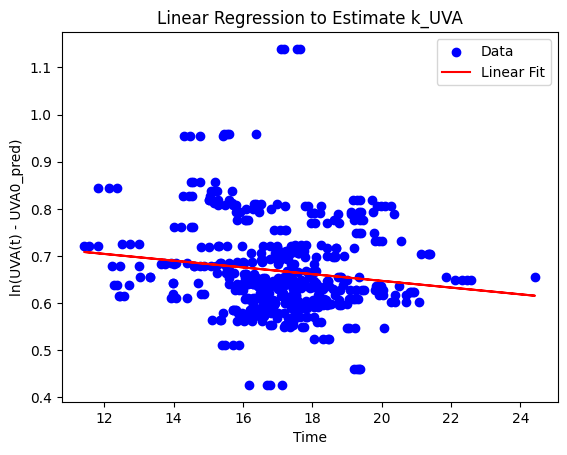

In [ ]:
#file_path = 'Ozoninput.xlsx'
#Ozoninput = pd.read_excel(file_path)
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/uvmodel.ipynb"
k_UVA, Ozoninput = UVAdecayrate(Ozoninput)

# **Modeling Ozone concentration using the combined Ozone model**

## **Setting the dataset**

In [ ]:
#file_path = 'PIMSLIMSfinal2020-2025.xlsx'
file_path = 'Ozoninput_3_newvolumes.xlsx'
Ozoninput = pd.read_excel(file_path)

In [ ]:
before = len(Ozoninput)
Ozoninput = Ozoninput.dropna(subset=['CT_All'])
after = len(Ozoninput)
print(f"Dropped {before - after} rows with NaN in the selected column.")
print(f"Remaining rows: {after}")

Dropped 0 rows with NaN in the selected column.
Remaining rows: 518


## **Feature selection, Pearson and Spearman correlations, and SOMs**

2.1.3
Available columns in the dataset:
1. Date
2. hour
3. month
4. Chamber
5. WaterTemperature
6. RFUV
7. RFTurbidity
8. FlowRate
9. Ozonedosage
10. Volume_old
11. Residencetime_old
12. WaterTemperature_1
13. WaterTemperature_2
14. WaterTemperature_3
15. WaterTemperature_4
16. WaterTemperature_5
17. RFturbidity_1
18. RFturbidity_2
19. RFturbidity_3
20. RFturbidity_4
21. RFturbidity_5
22. FlowRate_1
23. FlowRate_2
24. FlowRate_3
25. FlowRate_4
26. FlowRate_5
27. Ozonedosage_1
28. Ozonedosage_2
29. Ozonedosage_3
30. Ozonedosage_4
31. Ozonedosage_5
32. T_2_old
33. T_3_old
34. T_4_old
35. T_5_old
36. T_6_old
37. T_7_old
38. T_8_old
39. T_9_old
40. T_10_old
41. CT_1_old
42. CT_2_old
43. CT_3_old
44. CT_4_old
45. CT_5_old
46. CT_6_old
47. CT_7_old
48. CT_8_old
49. CT_9_old
50. CT_All_old
51. O3_2_old
52. O3_3_old
53. O3_4_old
54. O3_5_old
55. O3_6_old
56. O3_7_old
57. O3_8_old
58. O3_9_old
59. O3_10_old
60. Ko3
61. UVA0_pred
62. OzoneYield
63. Bromate_RapidSandfiltration_inlet
64. Bromide_O

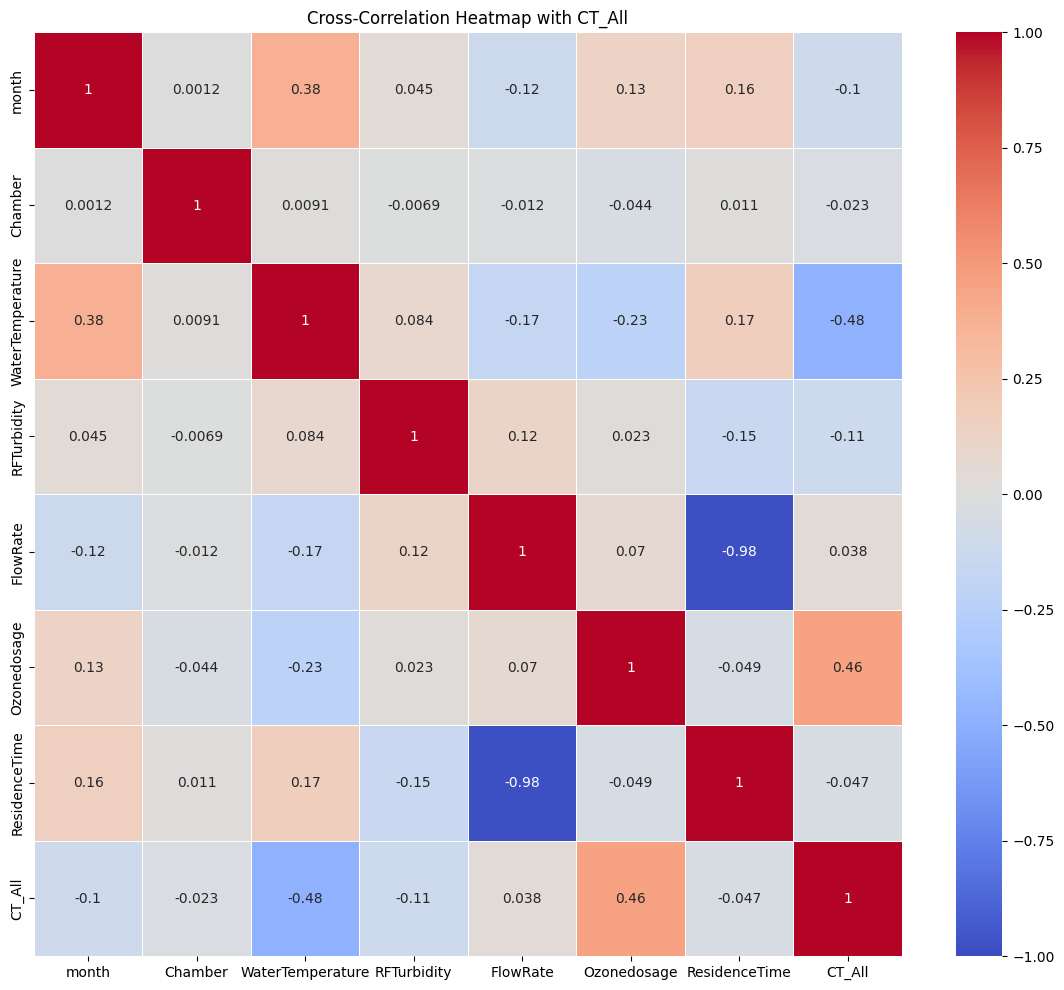


Pearson Correlation:
CT_All              1.000000
Ozonedosage         0.457146
FlowRate            0.037509
Chamber            -0.023454
ResidenceTime      -0.046635
month              -0.104858
RFTurbidity        -0.109515
WaterTemperature   -0.479528
Name: CT_All, dtype: float64


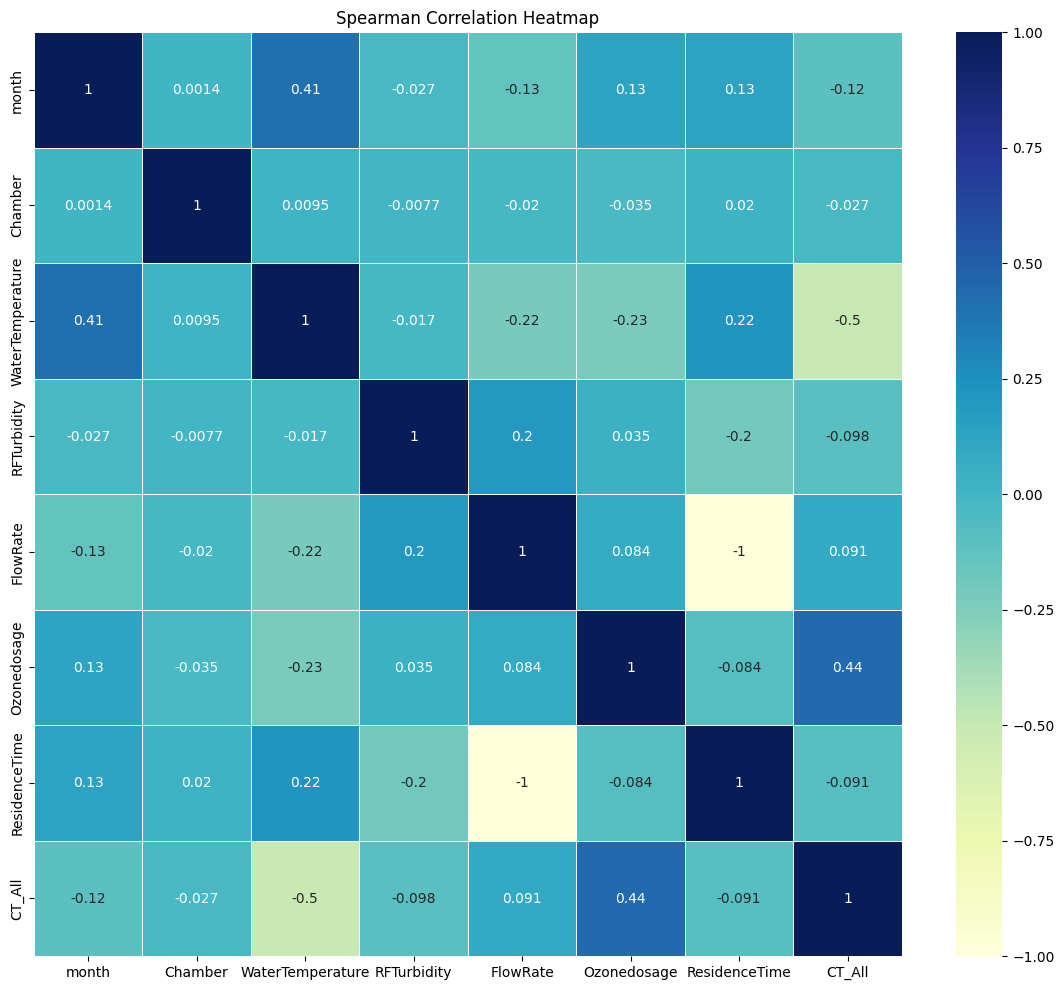


Spearman Correlation:
CT_All              1.000000
Ozonedosage         0.441430
FlowRate            0.091186
Chamber            -0.026940
ResidenceTime      -0.091186
RFTurbidity        -0.098470
month              -0.116385
WaterTemperature   -0.502908
Name: CT_All, dtype: float64

Greedy Feature Selection (SFS with Linear Regression):
Selected Features: ['month', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'ResidenceTime']

Mutual Information:
WaterTemperature    0.338078
month               0.208656
Ozonedosage         0.203416
RFTurbidity         0.099068
FlowRate            0.021331
ResidenceTime       0.019624
Chamber             0.000000
dtype: float64

L1 Regularization (LassoCV):
WaterTemperature    0.146851
Ozonedosage         0.133480
month               0.000000
Chamber             0.000000
RFTurbidity         0.000000
FlowRate            0.000000
ResidenceTime       0.000000
dtype: float64

Permutation Importance (RandomForest):
WaterTemperature    0.794

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/ozonemodel.ipynb"
X,y,input_features, target_variable,models_info = plot_cross_correlation(Ozoninput)

## **Select the Co3 inputs and calculate average Ko3**

In [ ]:
#CO3_t=Ozoninput.iloc[:,50:59]
CO3_t=Ozoninput.iloc[:,80:89]
Ko3=np.mean(Ozoninput['Ko3'])
#T=Ozoninput.iloc[:,31:40]
T=Ozoninput.iloc[:,98:107]
k_UVA = 0

## **Ozone exposure model**

2.1.3

Select a model:
1. Random Forest
2. XGBoost
3. Multi ensemble Random Forest
4. Multi ensemble XGBoost
5. Random Forest - XGBoost combination
6. Random Forest - Combination of 8 top-8 most important features (as per feature importance methods)
7. XGBoost - Combination of 8 top-8 most important features (as per feature importance methods)
8. Random Forest & XGBoost - Combination of 8 top-8 most important features (as per feature importance methods)
9. Gradient Boosting
10. AdaBoost
11. LightGBM
12. Linear Regression
13. Random Forrest - XGBoost - GBoost ensemble of up to 18 models
14. Physics-Informed MLP
15. XTC - hybrid model
16. Ensemble of Best Models - Weighted
Enter the number corresponding to your choice:2
Set the testing size(e.g. 0.1 = 10% for testing):0.2
Set the random state:42
Set the folder name:XGB 8 features


[I 2026-09-02 10:19:20,586] A new study created in memory with name: no-name-daf5bf3d-f388-48f6-9230-8ad27b5f2bc6


Running Bayesian Optimization with Optuna...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-09-02 10:19:21,601] Trial 0 finished with value: 0.47417709975780814 and parameters: {'n_estimators': 950, 'max_depth': 2, 'learning_rate': 0.07409442626236955}. Best is trial 0 with value: 0.47417709975780814.
[I 2026-09-02 10:19:26,160] Trial 1 finished with value: 0.38088799178856403 and parameters: {'n_estimators': 840, 'max_depth': 10, 'learning_rate': 0.29231608741072523}. Best is trial 0 with value: 0.47417709975780814.
[I 2026-09-02 10:19:29,651] Trial 2 finished with value: 0.40658468560142247 and parameters: {'n_estimators': 586, 'max_depth': 9, 'learning_rate': 0.055688869605358286}. Best is trial 0 with value: 0.47417709975780814.
[I 2026-09-02 10:19:30,163] Trial 3 finished with value: 0.4472910654529617 and parameters: {'n_estimators': 120, 'max_depth': 9, 'learning_rate': 0.43022191213053923}. Best is trial 0 with value: 0.47417709975780814.
[I 2026-09-02 10:19:30,456] Trial 4 finished with value: 0.49082183559346715 and parameters: {'n_estimators': 71, 'max_dept

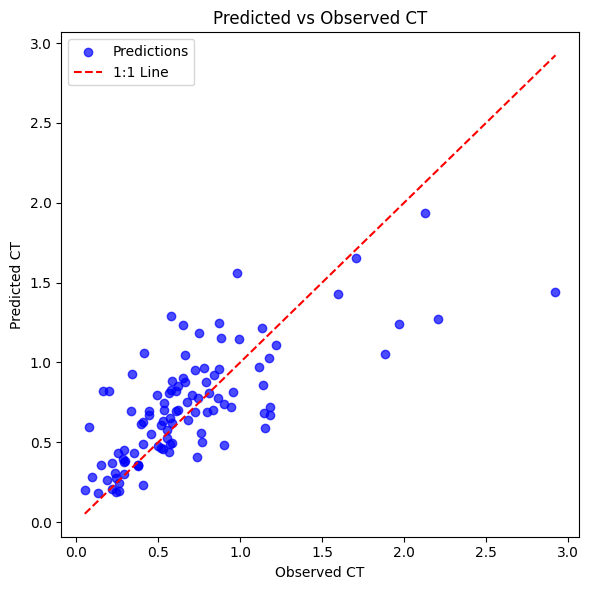

XGBoost - Feature Importance


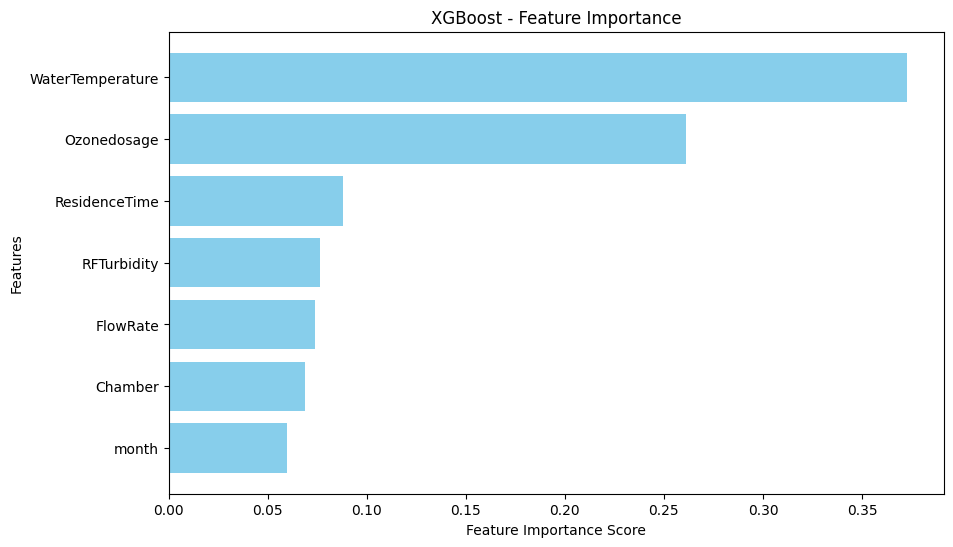

XGBoost - SHAP Summary


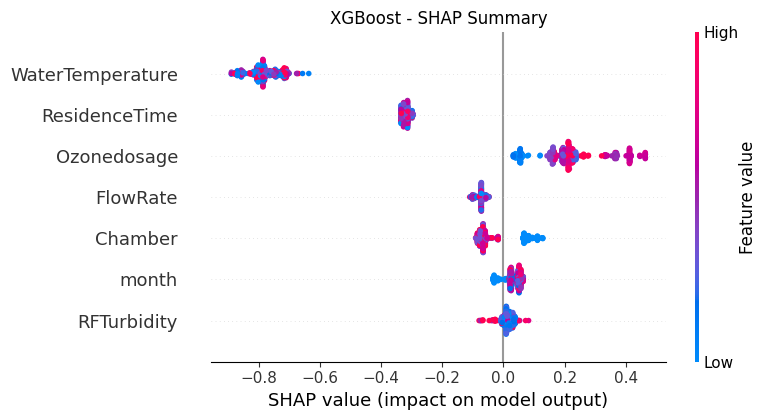

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/ozonemodel.ipynb"
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/X-TFCmodel.ipynb"
Vol = [68.4, 71.08, 72.96, 96.9, 145.82, 152.15, 327.21, 360.43, 537.15, 573.86]
voldiff = np.diff(Vol).reshape(-1, 1)
#XTC_model, CT_pred_xtfc, CT_pred_hybrid, Xtr_hybrid, Xte_hybrid,k_train,hybrid_features= X_TFC_CT_compartment_model(X,y,T,voldiff)
best_model, mae, mse, rmse, r2, si, kge, y_test, y_pred = predict_ozone_exposure(X, y, input_features, target_variable, k_UVA,CO3_t,Ko3,T, models_info,voldiff)

## **Daily prediction graphs and comparison with calculated estimations and risks limits**

In [ ]:
file_path = 'PIMSLIMSfinal2020-2025_newvolumes.xlsx'
ozoneprint = pd.read_excel(file_path)

Set the start date in the format of 2024-10-01):2024-07-01
Set the start hour (0-23):12
Set the end date in the format of 2024-10-01):2024-07-20
Set the end hour (0-23):12
Set the chamber (1-4):2
Predicting using simple model: xgb_7features_newvol.pkl

--- Sensitivity Analysis ---
Available features: ['Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'ResidenceTime', 'month']
Which feature would you like to vary? Ozonedosage
Enter percentage changes separated by commas (e.g. -10, 10, 20): -2,-4,-6


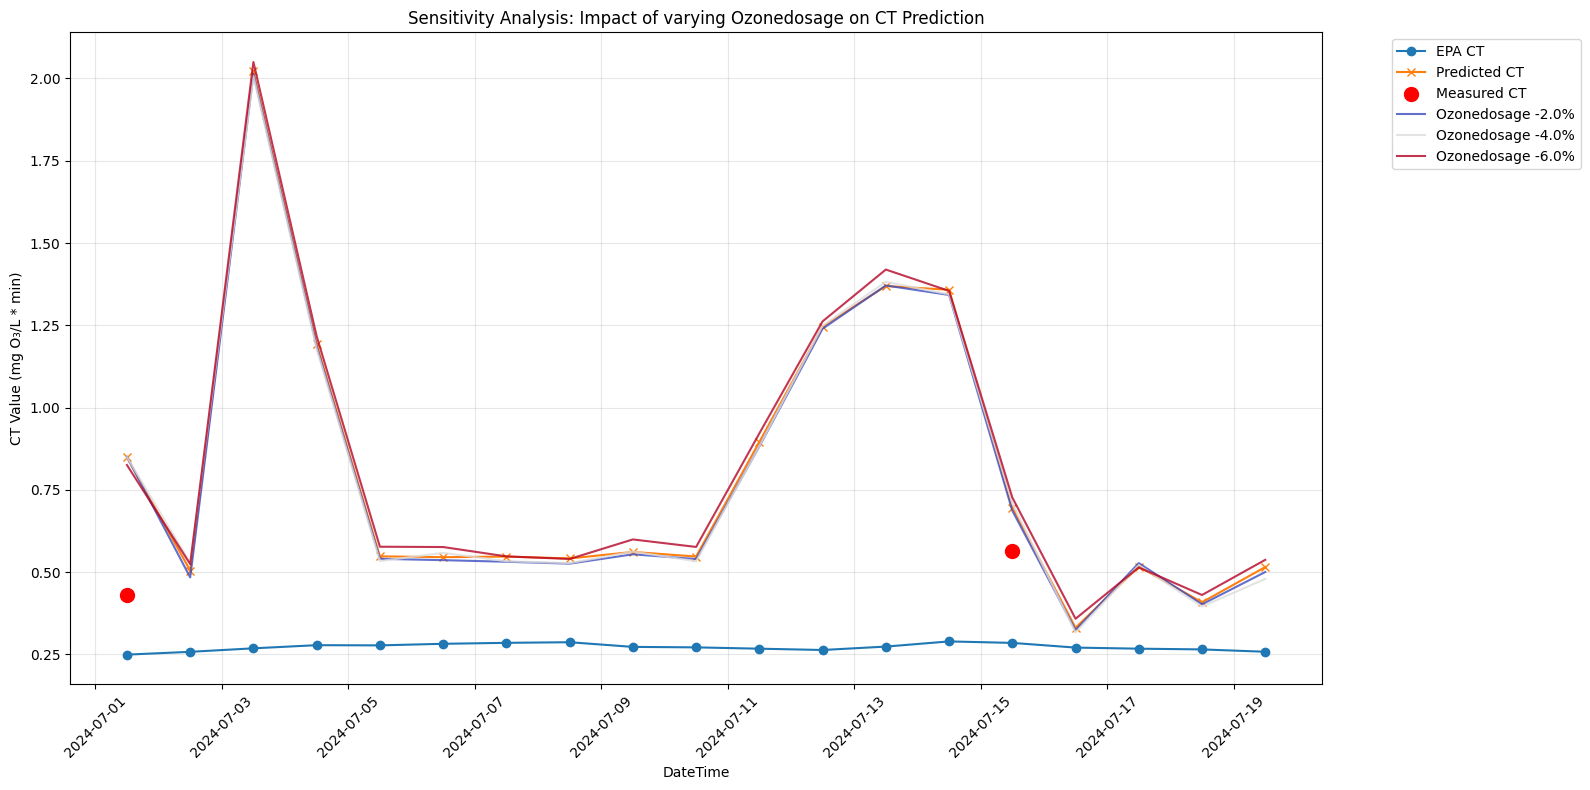

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/predgraphs.ipynb"
filtered_df, y_pred = ozoneplots(ozoneprint)

# **Modeling Bromate concentration in the ozonation outlet**

## **Replace or remove NAN values of the selected parameters**

In [ ]:
file_path = 'PIMSLIMSfinal2020-2025_newvolumes.xlsx'
bromate = pd.read_excel(file_path)
#Convert and prepare dataset
mask = bromate['Bromide_Ozonation_inlet'].notna() & bromate['Bromate_WTP_outlet'].isna()
bromate.loc[mask, 'Bromate_WTP_outlet'] = bromate['Bromate_WTP_outlet'].bfill()
before = len(bromate)
bromateinput = bromate.dropna(subset=['Bromide_Ozonation_inlet'])
after = len(bromateinput)
print(f"Dropped {before - after} rows with NaN in the selected column.")
print(f"Remaining rows: {after}")
output_path = 'Bromateinput_newvolumes.xlsx'
bromateinput.to_excel(output_path, index=False)

Dropped 172640 rows with NaN in the selected column.
Remaining rows: 1032


In [ ]:
input_path = 'Bromateinput_newvolumes.xlsx'
bromateinput = pd.read_excel(input_path)

### **Replace CT NAN values with predicted CT values**

In [ ]:
missing_mask = bromateinput['CT_All'].isna()
input_features = ['hour', 'month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Residencetime']
X_missing = bromateinput.loc[missing_mask, input_features]
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
predictions = ctpredict(X_missing)
print(f"Rows to fill: {missing_mask.sum()}")
print(f"Predictions received: {len(predictions)}")
bromateinput.loc[missing_mask, 'CT_All'] = predictions

Predicting using simple model: xgb_7features_newvolumes.pkl
Rows to fill: 824
Predictions received: 824


## **Feature selection, Pearson and Spearman correlations, and SOMs**

2.1.3
Available columns in the dataset:
1. Date
2. hour
3. month
4. Chamber
5. WaterTemperature
6. RFUV
7. RFTurbidity
8. FlowRate
9. Ozonedosage
10. Volume
11. Residencetime
12. WaterTemperature_1
13. WaterTemperature_2
14. WaterTemperature_3
15. WaterTemperature_4
16. WaterTemperature_5
17. RFturbidity_1
18. RFturbidity_2
19. RFturbidity_3
20. RFturbidity_4
21. RFturbidity_5
22. FlowRate_1
23. FlowRate_2
24. FlowRate_3
25. FlowRate_4
26. FlowRate_5
27. Ozonedosage_1
28. Ozonedosage_2
29. Ozonedosage_3
30. Ozonedosage_4
31. Ozonedosage_5
32. Ko3
33. UVA0_pred
34. OzoneYield
35. Bromate_RapidSandfiltration_inlet
36. Bromide_Ozonation_inlet
37. Campylobacter _Rapid Sandfiltration_inlet
38. Coliformbacteria 37C_Ozonation_inlet
39. Coliformbacteria 37C_Ozonation_outlet
40. Coliform bacteria 37C_RapidSandfiltration_inlet
41. Bromate_WTP_outlet
42. UV-extinctie, 254 nm_Ozonation_inlet
43. UV-extinctie, 254 nm_Ozonation_outlet
44. CT Value EPA calculated
45. Log Removal
46. Bacteriological p

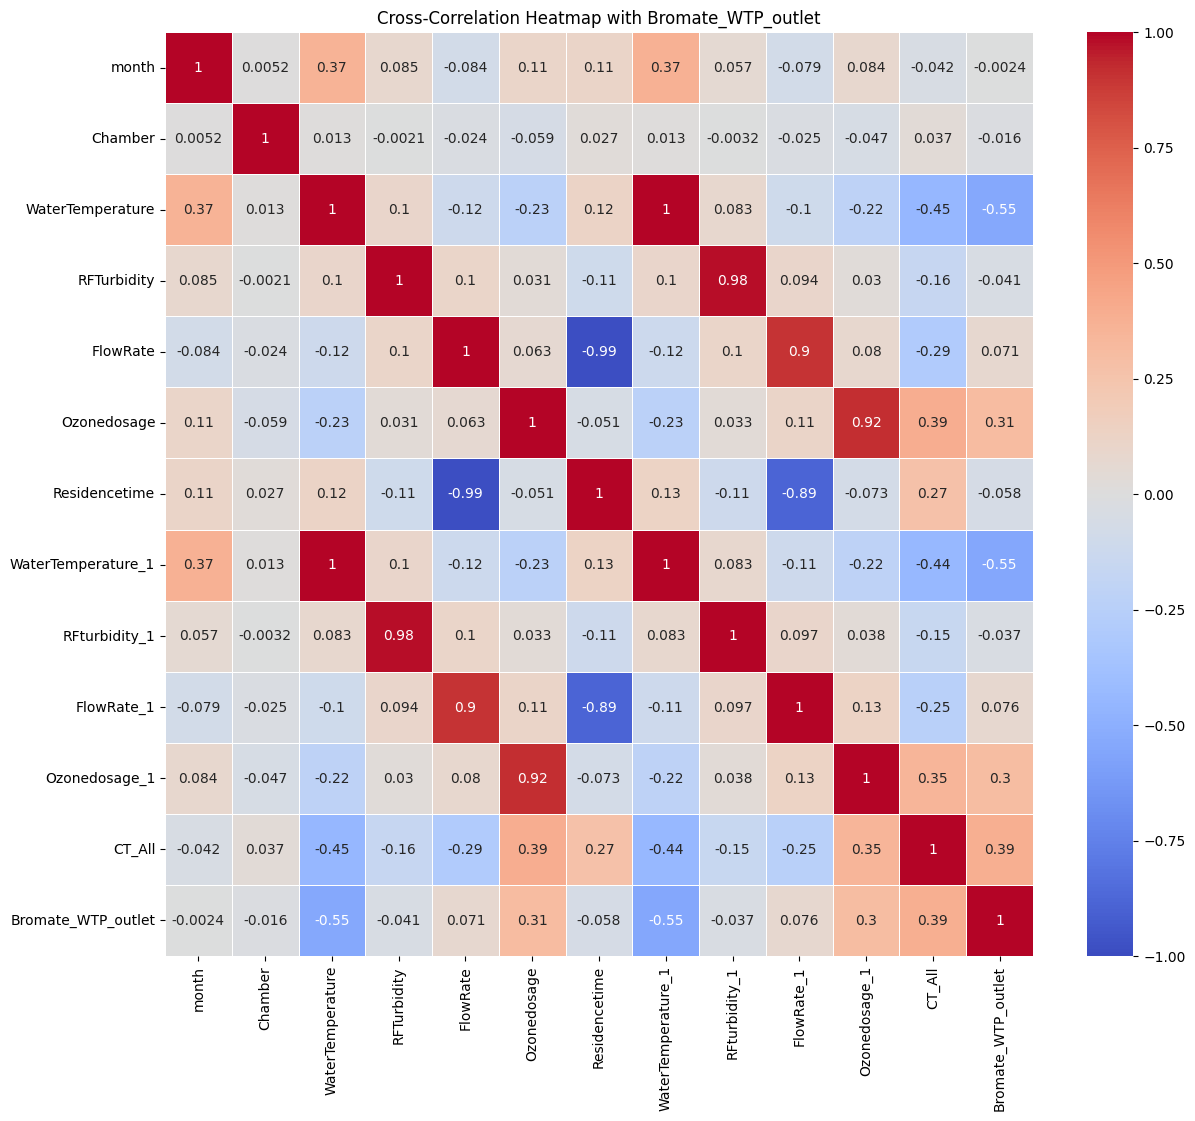


Pearson Correlation:
Bromate_WTP_outlet    1.000000
CT_All                0.388324
Ozonedosage           0.309900
Ozonedosage_1         0.298486
FlowRate_1            0.076145
FlowRate              0.071402
month                -0.002370
Chamber              -0.016145
RFturbidity_1        -0.037061
RFTurbidity          -0.040815
Residencetime        -0.057958
WaterTemperature     -0.546830
WaterTemperature_1   -0.547169
Name: Bromate_WTP_outlet, dtype: float64


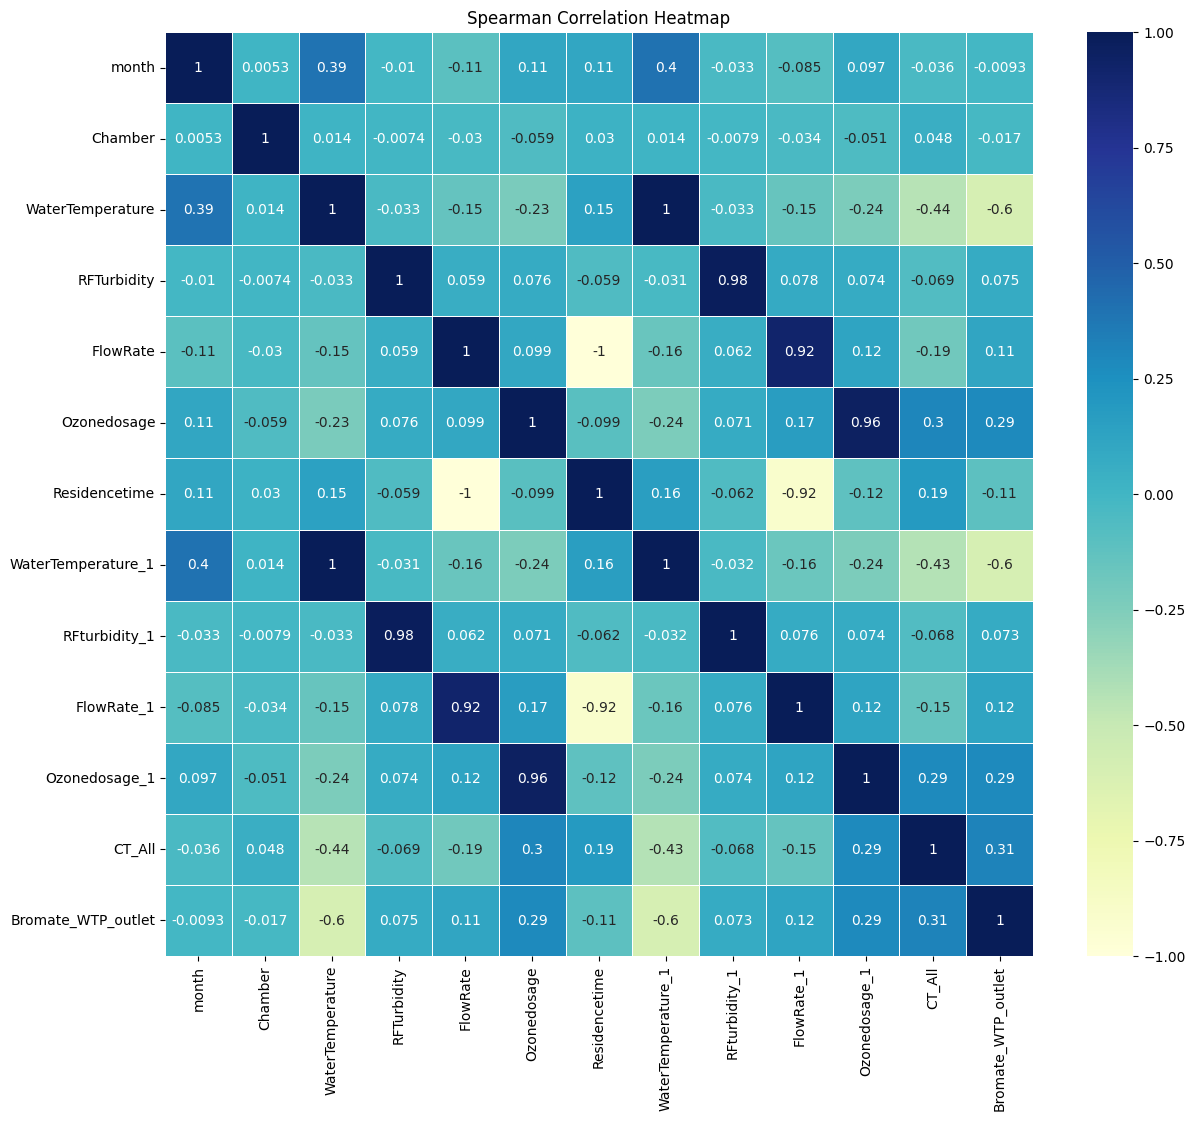


Spearman Correlation:
Bromate_WTP_outlet    1.000000
CT_All                0.313243
Ozonedosage           0.287079
Ozonedosage_1         0.285007
FlowRate_1            0.118584
FlowRate              0.111384
RFTurbidity           0.074512
RFturbidity_1         0.073068
month                -0.009271
Chamber              -0.016837
Residencetime        -0.111384
WaterTemperature_1   -0.600736
WaterTemperature     -0.601328
Name: Bromate_WTP_outlet, dtype: float64

Greedy Feature Selection (SFS with Linear Regression):
Selected Features: ['month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'WaterTemperature_1', 'RFturbidity_1', 'FlowRate_1', 'CT_All']

Mutual Information:
WaterTemperature_1    4.262131
WaterTemperature      4.236963
RFTurbidity           4.209522
RFturbidity_1         4.083134
month                 1.672744
FlowRate              0.297177
FlowRate_1            0.292006
Residencetime         0.280445
CT_All                0.156499
Ozonedosage_1         0.138809
Ozonedos

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/ozonemodel.ipynb"
X,y,input_features, target_variable,models_info = plot_cross_correlation(bromateinput)

## **Calibrate K values for von Gunten model**

In [ ]:
CT = bromateinput['CT_All'].values
ozone_dosage = bromateinput['Ozonedosage'].values
bromate_measured = bromateinput['Bromate_WTP_outlet'].values
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
k_calibrated, F_calibrated = k_calibrate(CT,ozone_dosage,bromate_measured)

Calibrated k: 0.5253909380069238, Calibrated F: 1.4601985302518914


## **Bromate in the ozonation outlet**


Select a model:
1. Random Forest
2. XGBoost
3. Gradient Boosting
4. AdaBoost
5. LightGBM
6. Physics-Informed MLP
7. van Gunten model
8. Linear Regression
2.1.3
Best AdaBoosting Hyperparameters: {'n_estimators': 1000, 'learning_rate': 0.1, 'estimator__max_depth': 10}
✅ Best AdaBoost model saved to: /content/drive/My Drive/Colab Notebooks/Ozonation model/ada_bromate_12_newvol_20.pkl

Model Performance:
MAE: 0.0661
MSE: 0.0241
RMSE: 0.1553
Scatter Index: 0.0960
R²: 0.9605


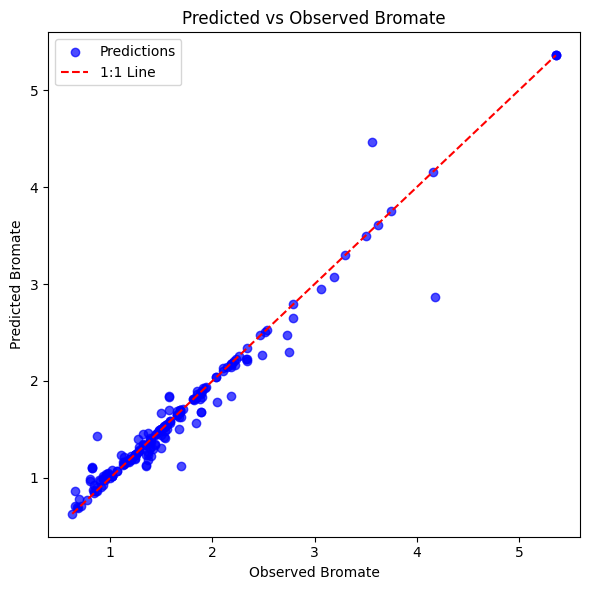

AdaBoost - Feature Importance


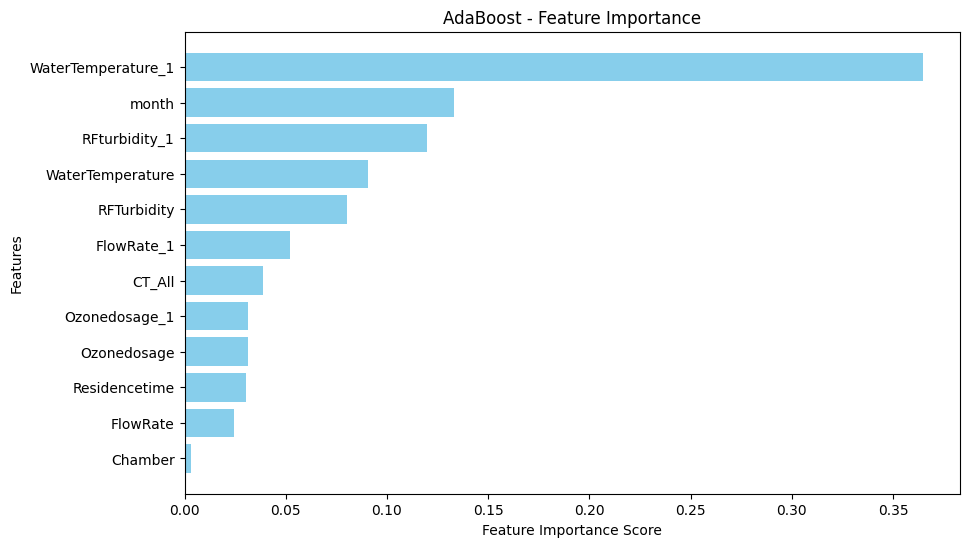

AdaBoost - SHAP Summary


  0%|          | 0/100 [00:00<?, ?it/s]

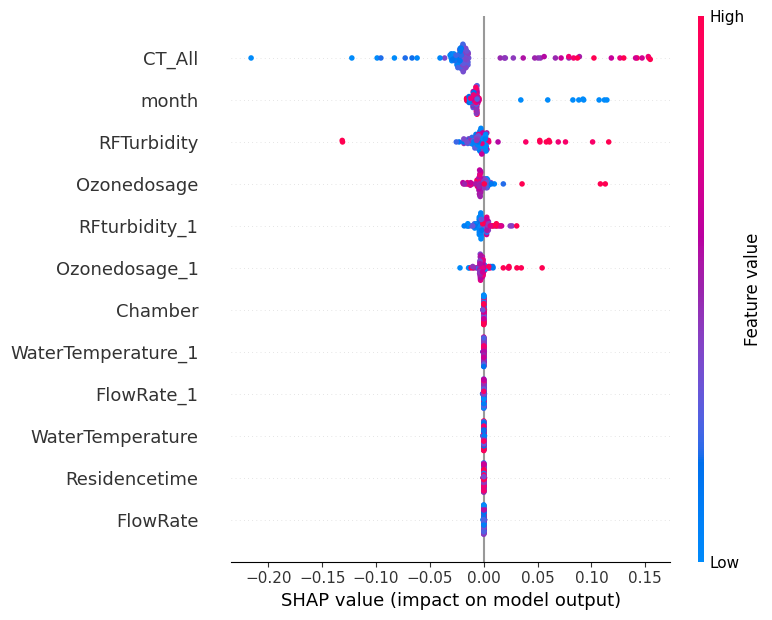

NameError: name 'model' is not defined

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
best_model, mae, mse, rmse, r2, si, y_test, y_pred = predict_bromate_outlet(X, y, input_features, target_variable, k_calibrated, F_calibrated, models_info)

In [ ]:
output_path = 'X_logremoval.xlsx'
X.to_excel(output_path, index=False)
output_path = 'y_logremoval.xlsx'
y.to_excel(output_path, index=False)

### **Replace CT NAN values with predicted CT values**

In [ ]:
missing_mask = bromateprint['CT_All'].isna()
input_features = ['hour', 'month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Residencetime']
X_missing = bromateprint.loc[missing_mask, input_features]
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
predictions = ctpredict(X_missing)
bromateprint.loc[missing_mask, 'CT_All'] = predictions

Predicting using simple model: GB_test_5_v2_42.pkl


## **Daily prediction graphs and comparison with calculated estimations and risks limits**

### **Load full dataset**

In [ ]:
file_path = 'PIMSLIMSfinal2020-2025.xlsx'
bromateprint = pd.read_excel(file_path)
bromateprint = bromateprint.drop(bromateprint.index[-1])

### **Replace CT NAN values with predicted CT values**

In [ ]:
missing_mask = bromateprint['CT_All'].isna()
input_features = ['hour', 'month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Residencetime']
X_missing = bromateprint.loc[missing_mask, input_features]
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
predictions = ctpredict(X_missing)
bromateprint.loc[missing_mask, 'CT_All'] = predictions

Predicting using simple model: GB_test_5_v2_42.pkl


### **Select period and chamber, predict outputs and plot results**

Set the start date in the format of 2024-10-01):2024-10-01
Set the start hour (0-23):10
Set the end date in the format of 2024-10-01):2024-10-20
Set the end hour (0-23):10
Set the chamber (1-4):3
✅ All models and scalers loaded successfully.

--- Bromate Sensitivity Analysis ---
Enter Ozonedosage change % (e.g., 20 or -15): -10
Enter 1 hour timelagged Ozonedosage change % (e.g., 20 or -15): -10
Recalculating CT for new dosage...
Predicting using simple model: GB_test_5_v2_42.pkl


NameError: name 'y_pred' is not defined

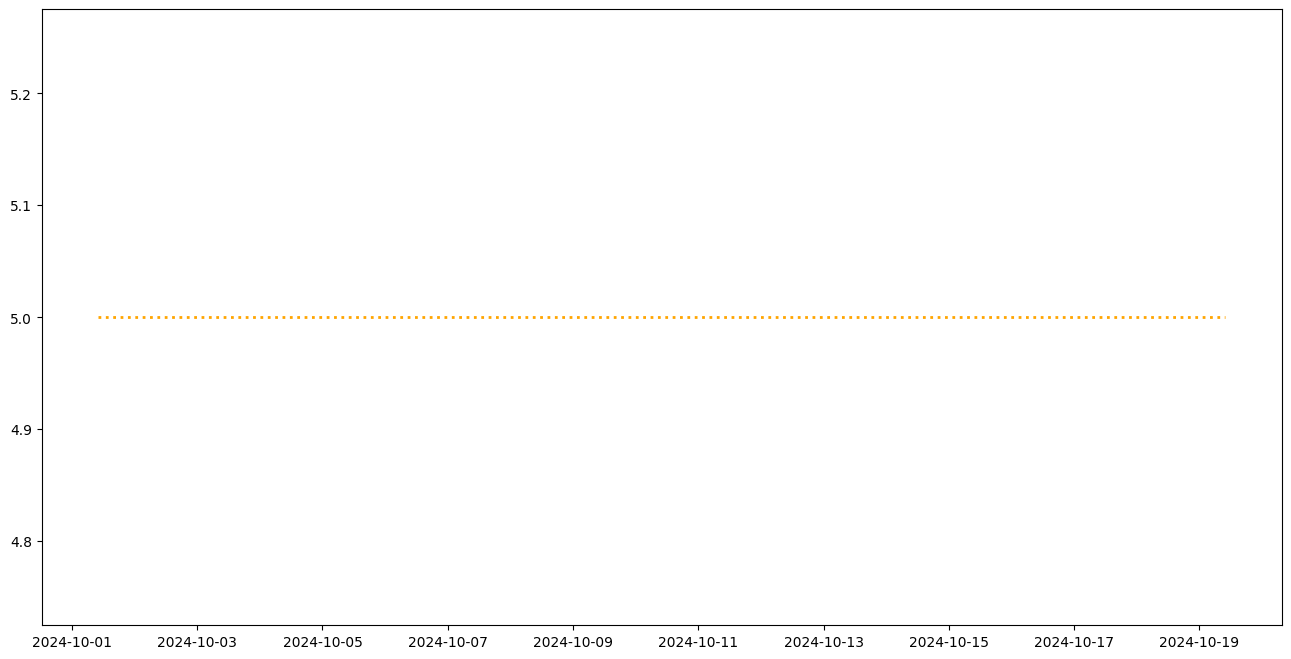

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/bromateadditionalmodel.ipynb"
filtered_df,y_pred = bromateplots(bromateprint)

# **Modeling the coliform bacteria in the ozonation outlet**

## **Calculate logarithmic removal ln(N/No)**


In [ ]:
mask = Ozoninput['Coliformbacteria 37C_Ozonation_inlet'].notna() & Ozoninput['Coliformbacteria 37C_Ozonation_outlet'].notna()
# Initialize column with NaN
Ozoninput['Coliform_log_removal'] = np.nan
Ozoninput['Ozone_logmean_concentration'] = np.nan
Ozoninput['K_Hom_estimation'] = np.nan

# Calculate log(col1/col2) only where both values exist
Ozoninput.loc[mask, 'Coliform_log_removal'] = np.log10(Ozoninput.loc[mask, 'Coliformbacteria 37C_Ozonation_outlet'] / Ozoninput.loc[mask, 'Coliformbacteria 37C_Ozonation_inlet'])
Ozoninput.loc[mask, 'Ozone_logmean_concentration'] = (Ozoninput.loc[mask, 'Ozonedosage'] - 0.012)/ np.log10(Ozoninput.loc[mask, 'Ozonedosage'] / 0.012)
Ozoninput.loc[mask,'K_Hom_observed'] = - Ozoninput.loc[mask, 'Coliform_log_removal'] /  (Ozoninput.loc[mask, 'Ozone_logmean_concentration'] * Ozoninput.loc[mask, 'ResidenceTime']**2)

In [ ]:
Ozoninput.to_excel("Ozoninput_3_newvolumes.xlsx", index=False)

## **Replace or remove NAN values of the selected parameters**


In [ ]:
file_path = 'PIMSLIMSfinal2020-2025_newvolumes.xlsx'
colbacteria = pd.read_excel(file_path)
#Convert and prepare dataset
mask = colbacteria['Coliformbacteria 37C_Ozonation_inlet'].notna() & colbacteria['Coliformbacteria 37C_Ozonation_outlet'].notna()
before = len(colbacteria)
colbacteriainput = colbacteria.dropna(subset=['Coliformbacteria 37C_Ozonation_inlet', 'Coliformbacteria 37C_Ozonation_outlet'])
after = len(colbacteriainput)
print(f"Dropped {before - after} rows with NaN in the selected column.")
print(f"Remaining rows: {after}")
output_path = 'Colbacteriainput_newvolumes.xlsx'
colbacteriainput.to_excel(output_path, index=False)

Dropped 173357 rows with NaN in the selected column.
Remaining rows: 315


In [ ]:
colbacteriainput['K_Hom_estimation'] = - colbacteriainput['Coliform_log_removal'] /  (colbacteriainput['Ozone_logmean_concentration'] * colbacteriainput['Residencetime']**2)
output_path = 'Colbacteriainput_newvolumes.xlsx'
colbacteriainput.to_excel(output_path, index=False)

/tmp/ipykernel_615/225005237.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  colbacteriainput['K_Hom_estimation'] = - colbacteriainput['Coliform_log_removal'] /  (colbacteriainput['Ozone_logmean_concentration'] * colbacteriainput['Residencetime']**2)


In [ ]:
input_path = 'Colbacteriainput_newvolumes.xlsx'
colbacteriainput = pd.read_excel(input_path)

### **Replace CT NAN values with predicted CT values**

In [ ]:
missing_mask = colbacteriainput['CT_All'].isna()
input_features = ['hour', 'month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Residencetime']
X_missing = colbacteriainput.loc[missing_mask, input_features]
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/Khomandlogremovalmodel.ipynb"
predictions = ctpredict(X_missing)
colbacteriainput.loc[missing_mask, 'CT_All'] = predictions

Predicting using simple model: xgb_7features_newvolumes.pkl


## **Feature selection, Pearson and Spearman correlations, and SOMs**

2.1.3
Available columns in the dataset:
1. Date
2. hour
3. month
4. Chamber
5. WaterTemperature
6. RFUV
7. RFTurbidity
8. FlowRate
9. Ozonedosage
10. Volume
11. Residencetime
12. WaterTemperature_1
13. WaterTemperature_2
14. WaterTemperature_3
15. WaterTemperature_4
16. WaterTemperature_5
17. RFturbidity_1
18. RFturbidity_2
19. RFturbidity_3
20. RFturbidity_4
21. RFturbidity_5
22. FlowRate_1
23. FlowRate_2
24. FlowRate_3
25. FlowRate_4
26. FlowRate_5
27. Ozonedosage_1
28. Ozonedosage_2
29. Ozonedosage_3
30. Ozonedosage_4
31. Ozonedosage_5
32. Ko3
33. UVA0_pred
34. OzoneYield
35. Bromate_RapidSandfiltration_inlet
36. Bromide_Ozonation_inlet
37. Campylobacter _Rapid Sandfiltration_inlet
38. Coliformbacteria 37C_Ozonation_inlet
39. Coliformbacteria 37C_Ozonation_outlet
40. Coliform bacteria 37C_RapidSandfiltration_inlet
41. Bromate_WTP_outlet
42. UV-extinctie, 254 nm_Ozonation_inlet
43. UV-extinctie, 254 nm_Ozonation_outlet
44. CT Value EPA calculated
45. Log Removal
46. Bacteriological p

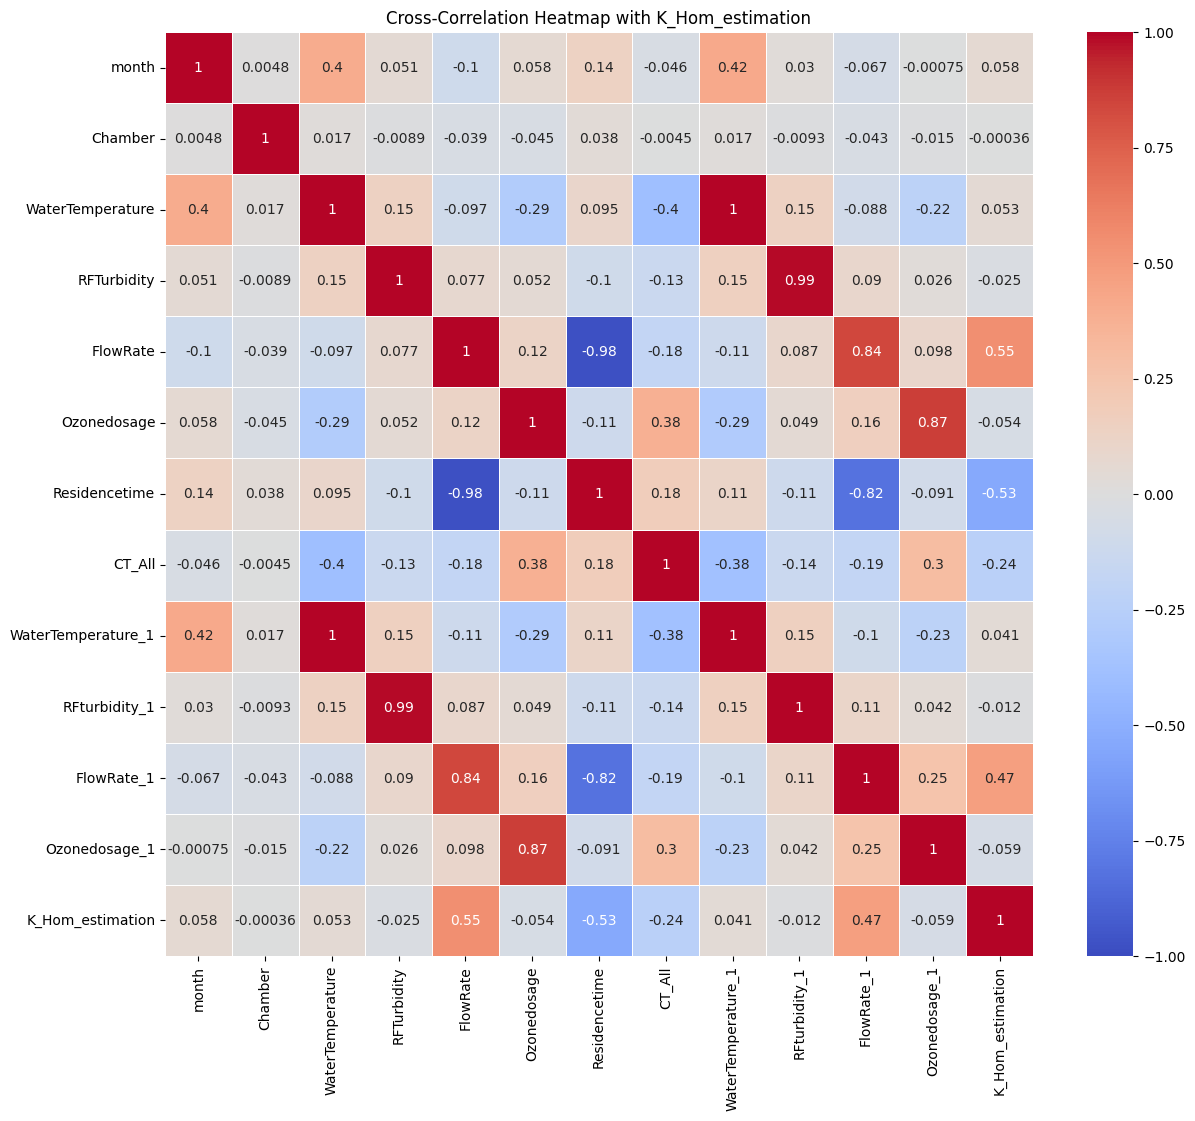


Pearson Correlation:
K_Hom_estimation      1.000000
FlowRate              0.554019
FlowRate_1            0.473778
month                 0.058281
WaterTemperature      0.053390
WaterTemperature_1    0.040798
Chamber              -0.000358
RFturbidity_1        -0.012366
RFTurbidity          -0.025308
Ozonedosage          -0.053546
Ozonedosage_1        -0.059344
CT_All               -0.239500
Residencetime        -0.531744
Name: K_Hom_estimation, dtype: float64


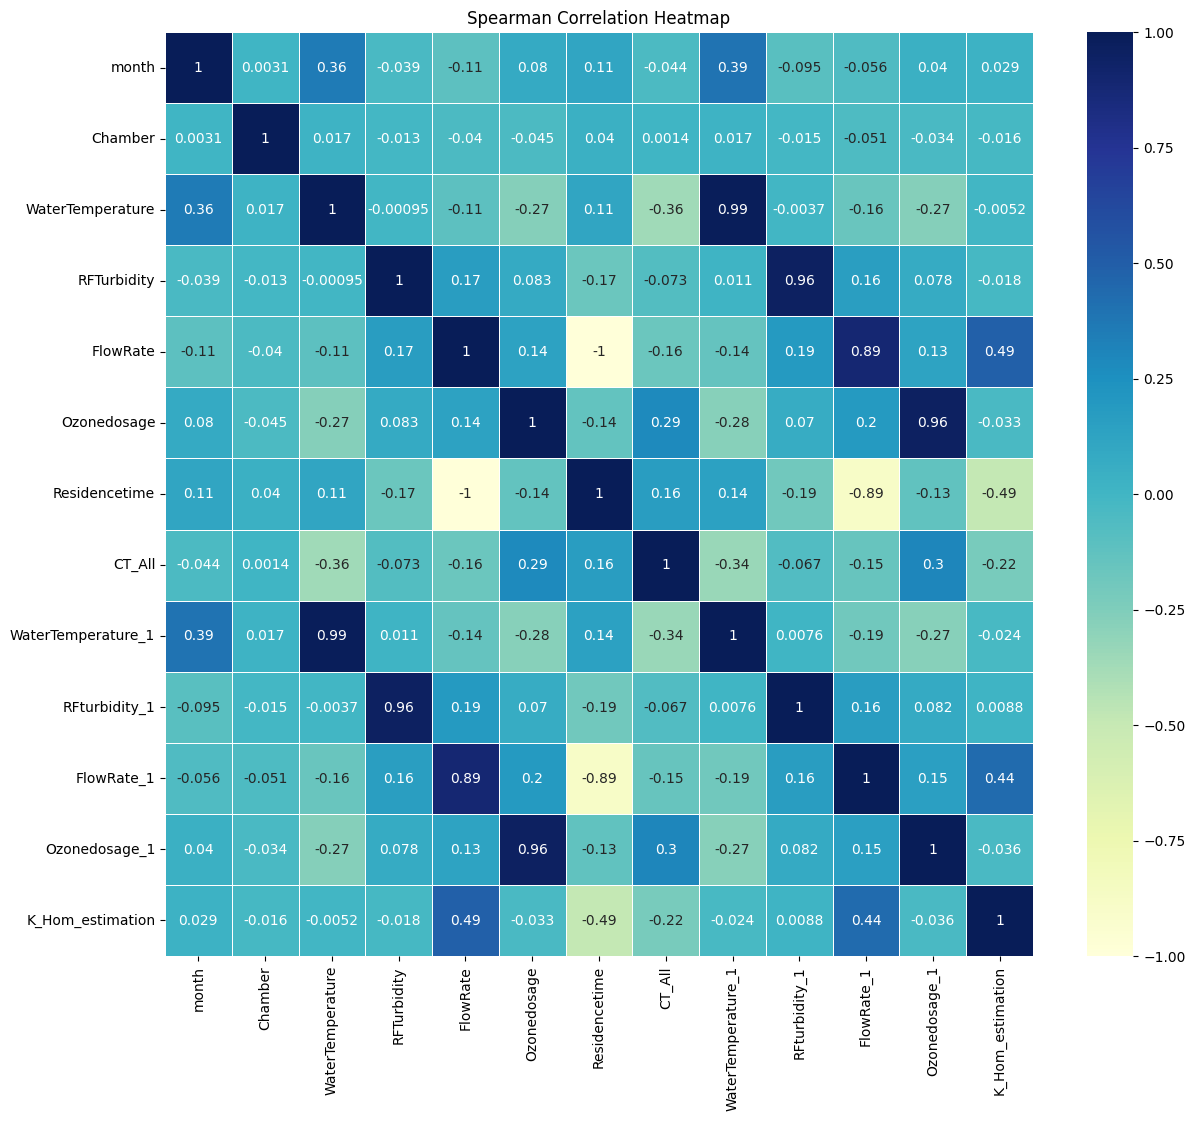


Spearman Correlation:
K_Hom_estimation      1.000000
FlowRate              0.486912
FlowRate_1            0.436090
month                 0.029176
RFturbidity_1         0.008817
WaterTemperature     -0.005161
Chamber              -0.016290
RFTurbidity          -0.017885
WaterTemperature_1   -0.024335
Ozonedosage          -0.032859
Ozonedosage_1        -0.036210
CT_All               -0.223481
Residencetime        -0.486912
Name: K_Hom_estimation, dtype: float64

Greedy Feature Selection (SFS with Linear Regression):
Selected Features: ['month', 'Chamber', 'FlowRate', 'Ozonedosage', 'Residencetime', 'CT_All', 'WaterTemperature_1', 'FlowRate_1']

Mutual Information:
WaterTemperature_1    0.624205
WaterTemperature      0.605129
RFTurbidity           0.600389
RFturbidity_1         0.576960
month                 0.465513
Residencetime         0.462768
FlowRate              0.457179
FlowRate_1            0.350489
CT_All                0.218649
Ozonedosage           0.121710
Ozonedosage_1     

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 9.83212098723367e-06, tolerance: 1.598426710558693e-06
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 6.187020463754508e-05, tolerance: 1.598426710558693e-06
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 0.00011399649637576156, tolerance: 1.598426710558693e-06
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descen

RFTurbidity           0.259286
FlowRate_1            0.186626
FlowRate              0.179874
CT_All                0.157011
Residencetime         0.138664
RFturbidity_1         0.078698
Ozonedosage           0.057094
WaterTemperature_1    0.049670
WaterTemperature      0.045082
Ozonedosage_1         0.032551
month                 0.026572
Chamber               0.002486
dtype: float64


In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/ozonemodel.ipynb"
X,y,input_features, target_variable,models_info = plot_cross_correlation(colbacteriainput)

## **Log removal in the ozonation process**


Select a model:
1. Random Forest
2. XGBoost
3. Gradient Boosting
4. AdaBoost
5. LightGBM
6. Physics-Informed MLP
7. Best 4 models weighted
8. Linear Regression
Enter the number corresponding to your choice:4
Set the testing size(e.g. 0.1 = 10% for testing):0.2
Set the random state:42
Set the folder name:AdaB 12 features
2.1.3
Best AdaBoosting Hyperparameters: {'n_estimators': 1000, 'learning_rate': 0.2, 'estimator__max_depth': 10}
Set the AdaBoost model name:ada_kcol_12_newvol_20.pkl
✅ Best AdaBoost model saved to: /content/drive/My Drive/Colab Notebooks/Ozonation model/ada_kcol_12_newvol_20.pkl

Model Performance:
Std obs: 0.0078
Std pred: 0.0068
R crosscor: 0.9467
Beta: 0.9835
gamma: 0.8886
Kling - Gupta - Efficiency (KGE): 0.8754

Performance for predicting inactivation rate k:
MAE: 0.0017
MSE: 0.0000
RMSE: 0.0026
Scatter Index: 0.1431
R²: 0.8895
Kling Gupta Efficiency: 0.8754

Model Performance:
Std obs: 0.7185
Std pred: 0.6045
R crosscor: 0.9205
Beta: 0.9904
gamma: 0.8494
Kling -

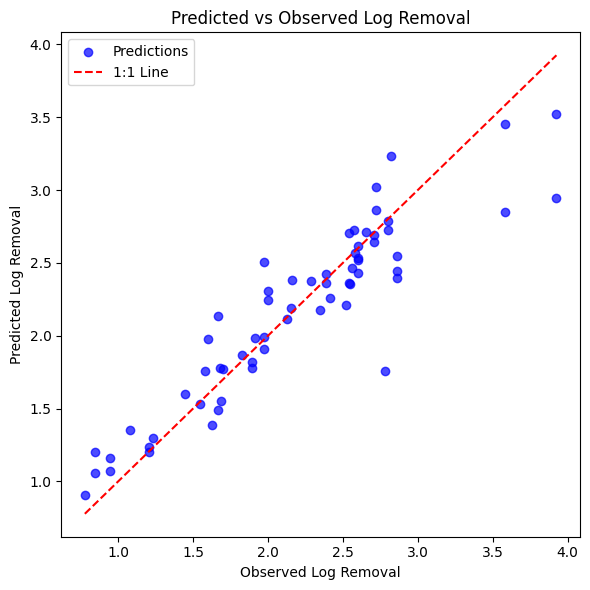

AdaBoost - Feature Importance


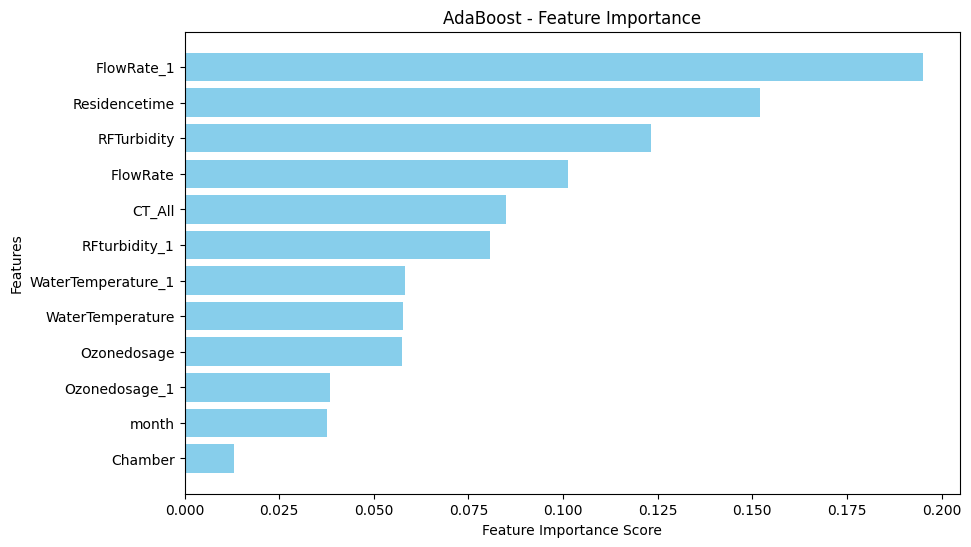

AdaBoost - SHAP Summary


  0%|          | 0/100 [00:00<?, ?it/s]

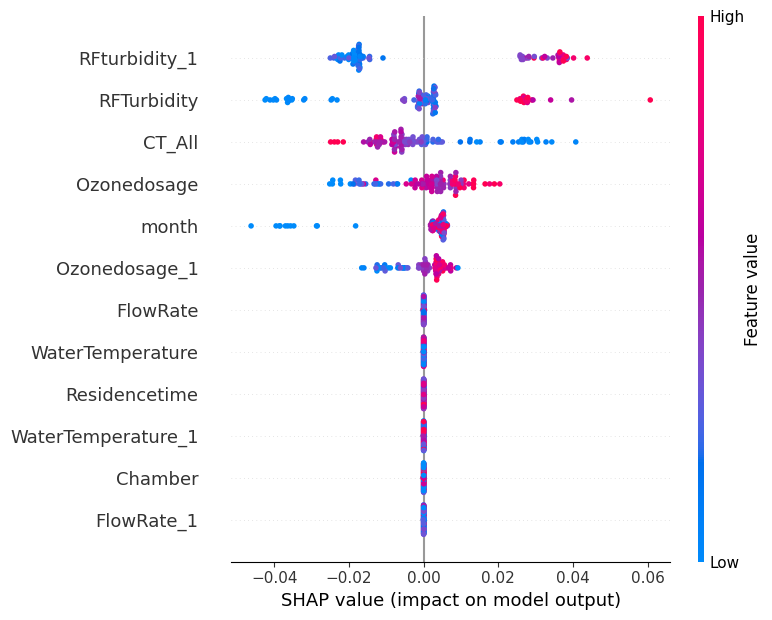

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/Khomandlogremovalmodel.ipynb"
log_removal_observed= colbacteriainput['Coliform_log_removal']
Clog=colbacteriainput['Ozone_logmean_concentration']
time=colbacteriainput['Residencetime']
best_model, mae, mse, rmse, r2, si, y_test, y_pred = predict_logremoval_outlet(X, y, input_features, target_variable, models_info,log_removal_observed,Clog,time)

## **Daily prediction graphs and comparison with calculated estimations and risks limits**

### **Load full dataset**

In [ ]:
file_path = 'PIMSLIMSfinal2020-2025.xlsx'
colprint = pd.read_excel(file_path)
colprint = colprint.drop(colprint.index[-1])

### **Replace CT NAN values with predicted CT values**

In [ ]:
missing_mask = colprint['CT_All'].isna()
input_features = ['hour', 'month', 'Chamber', 'WaterTemperature', 'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Residencetime']
X_missing = colprint.loc[missing_mask, input_features]
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/Khomandlogremovalmodel.ipynb"
predictions = ctpredict(X_missing)
colprint.loc[missing_mask, 'CT_All'] = predictions

Predicting using simple model: GB_test_5_v2_42.pkl


### **Select period and chamber, predict outputs and plot results**

Set the start date in the format of 2024-10-01):2023-11-01
Set the start hour (0-23):12
Set the end date in the format of 2024-10-01):2023-11-30
Set the end hour (0-23):12
Set the chamber (1-4):2
✅ All models and scalers loaded successfully.

--- Coliform Sensitivity Analysis ---
Enter Ozonedosage change % (e.g., 10 or -10): -10
Predicting using simple model: GB_test_5_v2_42.pkl


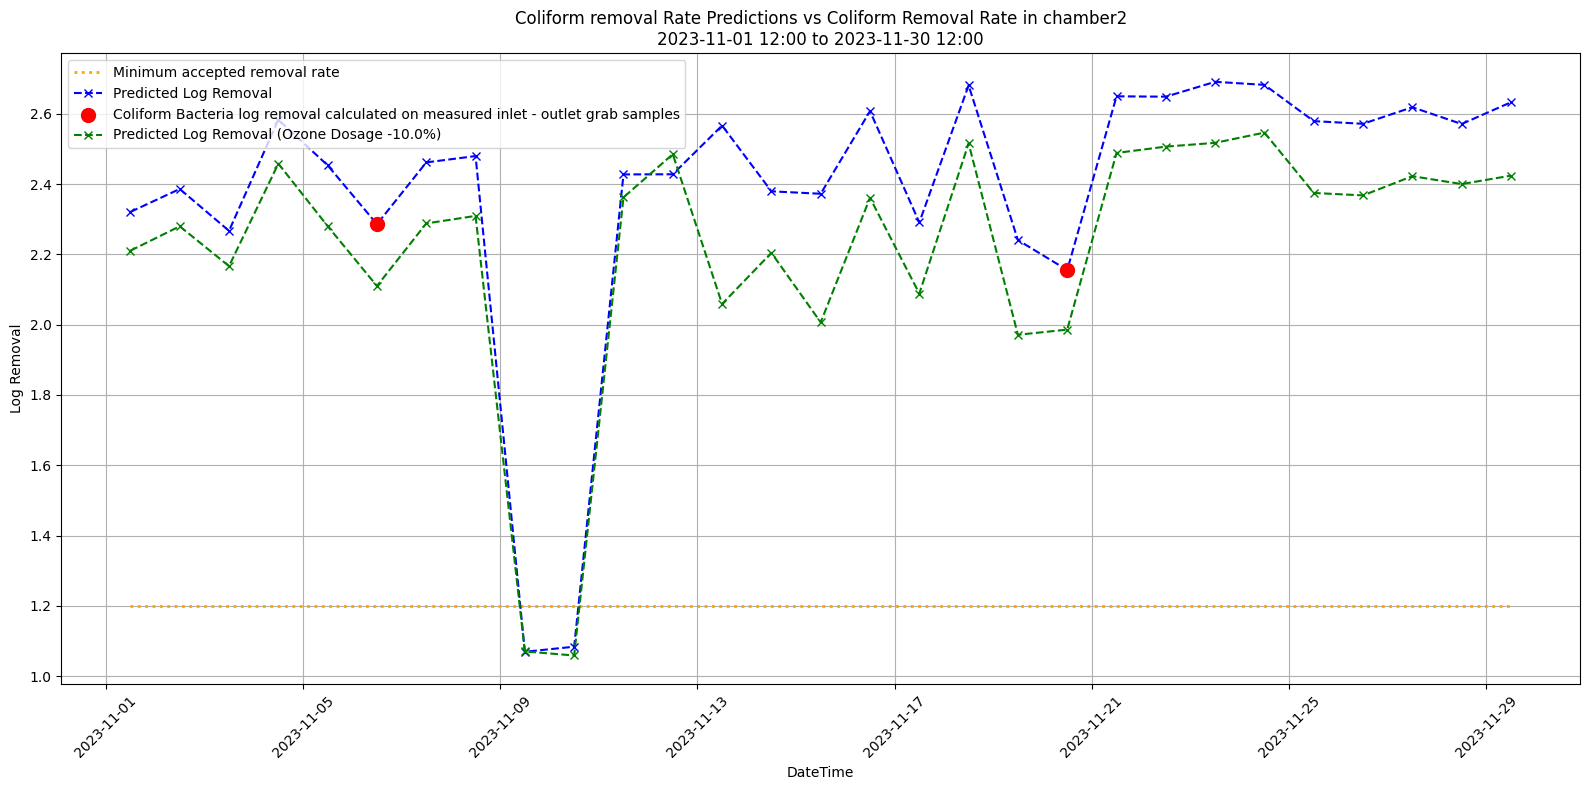

In [ ]:
%run "/content/drive/My Drive/Colab Notebooks/Ozonation model/Khomandlogremovalmodel.ipynb"
filtered_df,y_pred = colbactplots(colprint)

# **Akrivi test**

In [ ]:
!pip install numpy==1.26.4

In [ ]:
import joblib
import os
import numpy as np

In [ ]:
save_dir = "/content/drive/My Drive/Colab Notebooks/Ozonation model/OZONE BEST TRAINED MODELS/New dataset/Mix features"
#modelname="weightedensemble_model.pkl"
modelname="GB_test_5_v2_42.pkl"
featurescaler_path = os.path.join(save_dir, "feature_scaler.pkl")
targetscaler_path = os.path.join(save_dir, "target_scaler.pkl")
model_path = os.path.join(save_dir, modelname)
    #ensemble_model = joblib.load(model_path)
gb_model = joblib.load(model_path)

In [ ]:
joblib.dump(gb_model, 'GB_test_5_v2_42.joblib')

['GB_test_5_v2_42.joblib']

In [ ]:
if hasattr(gb_model, 'random_state'):
    gb_model.random_state = 42

for stage in gb_model.estimators_:
    for tree in stage:
        tree.random_state = 42

# 3. Save it again
joblib.dump(gb_model, 'GB_test_5_v2_42.joblib')
print("Model stripped of NumPy 2.0 generators and saved.")

Model stripped of NumPy 2.0 generators and saved.


In [ ]:
joblib.dump(gb_model, 'GB_test_5_v2_42.joblib')

['GB_test_5_v2_42.joblib']

In [ ]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import joblib


# Define the input type (Match the number of features your model has, e.g., 10)
num_features = model.n_features_in_
initial_type = [('float_input', FloatTensorType([None, num_features]))]

# Convert to ONNX
onx = convert_sklearn(gb_model, initial_types=initial_type)

with open("GB_test_5_v2_42.onnx", "wb") as f:
    f.write(onx.SerializeToString())
print("✅ Model exported to ONNX format!")

In [ ]:
import joblib

model_path = "/content/drive/My Drive/Colab Notebooks/Ozonation model/Bromate best model/adaboost_bromate_12_42.pkl"

loaded_model = joblib.load(model_path)

print("Object type:", type(loaded_model))
print("Has predict:", hasattr(loaded_model, "predict"))
print("Object:", loaded_model)

Object type: <class 'sklearn.ensemble._weight_boosting.AdaBoostRegressor'>
Has predict: True
Object: AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=10),
                  learning_rate=0.1, n_estimators=1000, random_state=42)


In [ ]:
joblib.dump(loaded_model, "adaboost_bromate_12_42_big.pkl", compress=3)

['adaboost_bromate_12_42_big.pkl']

In [ ]:
file_path = 'PIMSLIMSfinal2020-2025.xlsx'
bromate = pd.read_excel(file_path)

In [ ]:
bromate.columns

Index(['Date', 'hour', 'month', 'Chamber', 'WaterTemperature', 'RFUV',
       'RFTurbidity', 'FlowRate', 'Ozonedosage', 'Volume', 'Residencetime',
       'WaterTemperature_1', 'WaterTemperature_2', 'WaterTemperature_3',
       'WaterTemperature_4', 'WaterTemperature_5', 'RFturbidity_1',
       'RFturbidity_2', 'RFturbidity_3', 'RFturbidity_4', 'RFturbidity_5',
       'FlowRate_1', 'FlowRate_2', 'FlowRate_3', 'FlowRate_4', 'FlowRate_5',
       'Ozonedosage_1', 'Ozonedosage_2', 'Ozonedosage_3', 'Ozonedosage_4',
       'Ozonedosage_5', 'T_2', 'T_3', 'T_4', 'T_5', 'T_6', 'T_7', 'T_8', 'T_9',
       'T_10', 'CT_1', 'CT_2', 'CT_3', 'CT_4', 'CT_5', 'CT_6', 'CT_7', 'CT_8',
       'CT_9', 'CT_All', 'O3_2', 'O3_3', 'O3_4', 'O3_5', 'O3_6', 'O3_7',
       'O3_8', 'O3_9', 'O3_10', 'Ko3', 'UVA0_pred', 'OzoneYield',
       'Bromate_RapidSandfiltration_inlet', 'Bromide_Ozonation_inlet',
       'Campylobacter _Rapid Sandfiltration_inlet',
       'Coliformbacteria 37C_Ozonation_inlet',
       'Coliformb

In [ ]:
bromate = bromate.drop(columns=['T_2', 'T_3', 'T_4', 'T_5', 'T_6', 'T_7', 'T_8', 'T_9',
       'T_10', 'CT_1', 'CT_2', 'CT_3', 'CT_4', 'CT_5', 'CT_6', 'CT_7', 'CT_8',
       'CT_9', 'CT_All', 'O3_2', 'O3_3', 'O3_4', 'O3_5', 'O3_6', 'O3_7',
       'O3_8', 'O3_9', 'O3_10'])

In [ ]:
columns=['Date', 'hour', 'month', 'Chamber','T_1','T_2', 'T_3', 'T_4', 'T_5', 'T_6', 'T_7', 'T_8', 'T_9',
       'CT_1', 'CT_2', 'CT_3', 'CT_4', 'CT_5', 'CT_6', 'CT_7', 'CT_8',
       'CT_9', 'CT_All','o3_1', 'o3_2', 'o3_3', 'o3_4', 'o3_5', 'o3_6', 'o3_7',
       'o3_8', 'o3_9',]

In [ ]:
bromate_2['Date'] = bromate['Date'].values

In [ ]:
col = bromate_2.pop('Date')
bromate_2.insert(0, 'Date', col)

In [ ]:
bromate_2=bromate_2.drop(columns=['Date_x'])

In [ ]:
bromate_2.to_excel('PIMSLIMSfinal2020-2025_newvolumes.xlsx', index=False)

In [ ]:
bromate["Residencetime"]=bromate["Volume"] *60/bromate["FlowRate"]

In [ ]:
bromate.to_excel('PIMSLIMSfinal2020-2025_newvolumes.xlsx', index=False)